In [2]:
import sys
import tensorflow as tf
import keras

print("Python Version:", sys.version)
print("Python Executable:", sys.executable)

print("\nTensorFlow Version:", tf.__version__)
print("Keras Version:", keras.__version__)

print("\nAvailable Devices:")
print(tf.config.list_physical_devices())

Python Version: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:15:26) [Clang 20.1.8 ]
Python Executable: /opt/anaconda3/envs/week5-tf/bin/python

TensorFlow Version: 2.21.0
Keras Version: 3.15.1

Available Devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:
import tensorflow as tf
import numpy as np

# Load Fashion-MNIST dataset
fashion_mnist = tf.keras.datasets.fashion_mnist

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print("Dataset loaded successfully!")

print("\nTraining Data Shape:", x_train.shape)
print("Training Labels Shape:", y_train.shape)

print("\nTesting Data Shape:", x_test.shape)
print("Testing Labels Shape:", y_test.shape)

print("\nPixel Value Range:")
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

Dataset loaded successfully!

Training Data Shape: (60000, 28, 28)
Training Labels Shape: (60000,)

Testing Data Shape: (10000, 28, 28)
Testing Labels Shape: (10000,)

Pixel Value Range:
Minimum: 0
Maximum: 255


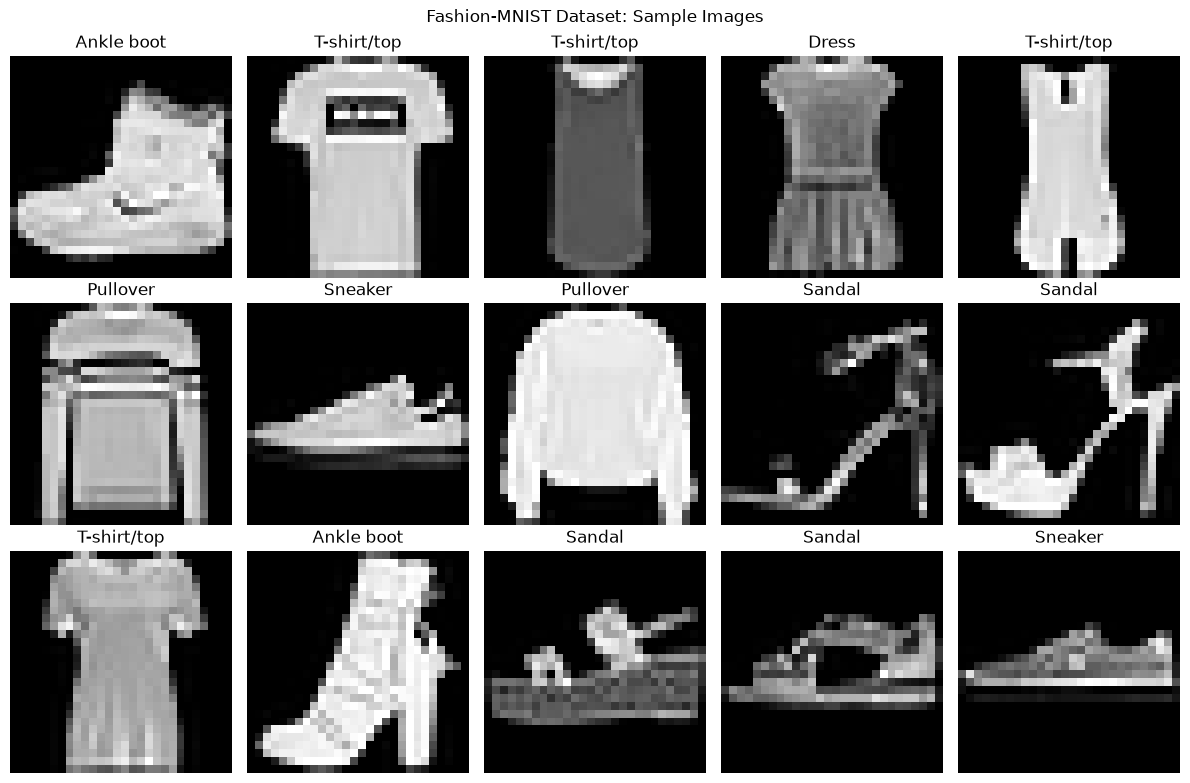

Number of categories: 10

Category Distribution:
0: T-shirt/top = 6000 images
1: Trouser = 6000 images
2: Pullover = 6000 images
3: Dress = 6000 images
4: Coat = 6000 images
5: Sandal = 6000 images
6: Shirt = 6000 images
7: Sneaker = 6000 images
8: Bag = 6000 images
9: Ankle boot = 6000 images


In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Names of all 10 categories
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Display 15 sample images
plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train[i], cmap="gray")

    label = y_train[i]

    plt.title(class_names[label])
    plt.axis("off")

plt.suptitle("Fashion-MNIST Dataset: Sample Images")
plt.tight_layout()
plt.show()

# Display category names and their counts
print("Number of categories:", len(class_names))

print("\nCategory Distribution:")
for i, name in enumerate(class_names):
    count = np.sum(y_train == i)
    print(f"{i}: {name} = {count} images")

In [5]:
# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Reshape images for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

print("\nNormalized Pixel Values:")
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)

Normalized Pixel Values:
Minimum: 0.0
Maximum: 1.0


In [6]:
from sklearn.model_selection import train_test_split

x_train_final, x_val, y_train_final, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training images:", x_train_final.shape)
print("Validation images:", x_val.shape)
print("Testing images:", x_test.shape)

print("\nTraining labels:", y_train_final.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

Training images: (54000, 28, 28, 1)
Validation images: (6000, 28, 28, 1)
Testing images: (10000, 28, 28, 1)

Training labels: (54000,)
Validation labels: (6000,)
Testing labels: (10000,)


In [7]:
from tensorflow import keras
from tensorflow.keras import layers

# Create the CNN model
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(10, activation="softmax")
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [9]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Reduce learning rate when validation loss stops improving
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001
)

# Train the CNN model
history = model.fit(
    x_train_final,
    y_train_final,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=128,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("CNN training completed successfully!")

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 28ms/step - accuracy: 0.7511 - loss: 0.6869 - val_accuracy: 0.8413 - val_loss: 0.4271 - learning_rate: 0.0010
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8386 - loss: 0.4487 - val_accuracy: 0.8700 - val_loss: 0.3484 - learning_rate: 0.0010
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.8609 - loss: 0.3877 - val_accuracy: 0.8858 - val_loss: 0.3047 - learning_rate: 0.0010
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.8727 - loss: 0.3552 - val_accuracy: 0.8950 - val_loss: 0.2895 - learning_rate: 0.0010
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 42ms/step - accuracy: 0.8806 - loss: 0.3290 - val_accuracy: 0.8980 - val_loss: 0.2749 - learning_rate: 0.0010
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.8876 - loss: 0.3093 - val_accuracy: 0.9028 - val_loss: 0.2649 - learning_rate: 0.0010
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.8918 - l

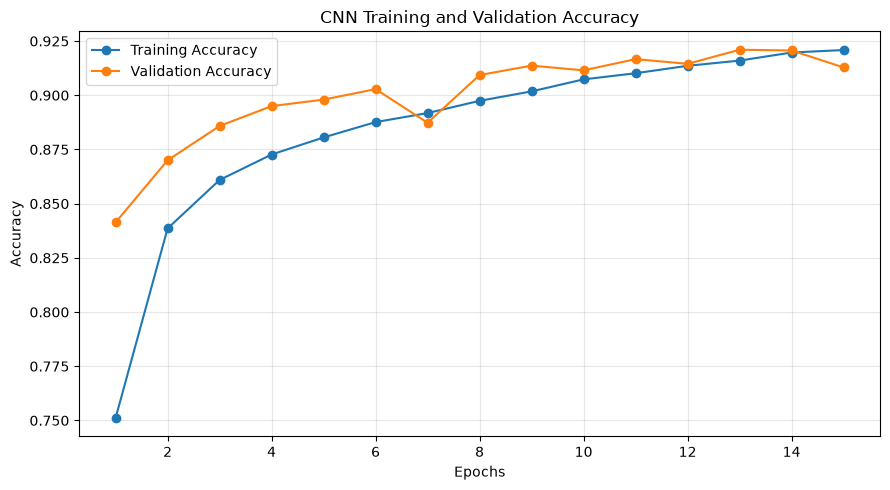

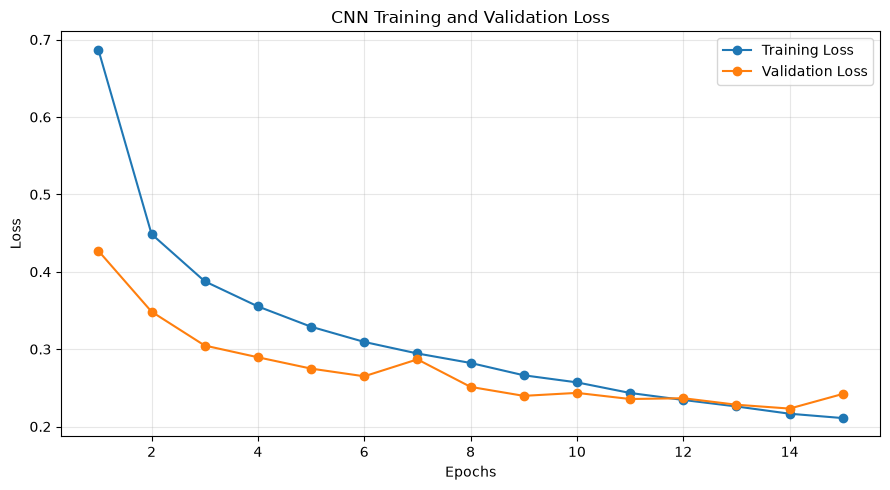

In [10]:
import matplotlib.pyplot as plt

# Get training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(train_accuracy) + 1)

# Plot accuracy
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_accuracy, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracy, marker="o", label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot loss
plt.figure(figsize=(9, 5))
plt.plot(epochs, train_loss, marker="o", label="Training Loss")
plt.plot(epochs, val_loss, marker="o", label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
# Evaluate the trained CNN on unseen test images
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nFINAL TEST RESULTS")
print("------------------------------")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9093 - loss: 0.2466

FINAL TEST RESULTS
------------------------------
Test Loss: 0.2466
Test Accuracy: 90.93 %


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
CLASSIFICATION REPORT
              precision    recall  f1-score   support

 T-shirt/top     0.8530    0.8590    0.8560      1000
     Trouser     0.9929    0.9800    0.9864      1000
    Pullover     0.8619    0.8610    0.8614      1000
       Dress     0.9114    0.9150    0.9132      1000
        Coat     0.8353    0.8980    0.8655      1000
      Sandal     0.9839    0.9780    0.9809      1000
       Shirt     0.7550    0.6780    0.7144      1000
     Sneaker     0.9450    0.9800    0.9622      1000
         Bag     0.9639    0.9890    0.9763      1000
  Ankle boot     0.9815    0.9550    0.9681      1000

    accuracy                         0.9093     10000
   macro avg     0.9084    0.9093    0.9085     10000
weighted avg     0.9084    0.9093    0.9085     10000



<Figure size 1100x900 with 0 Axes>

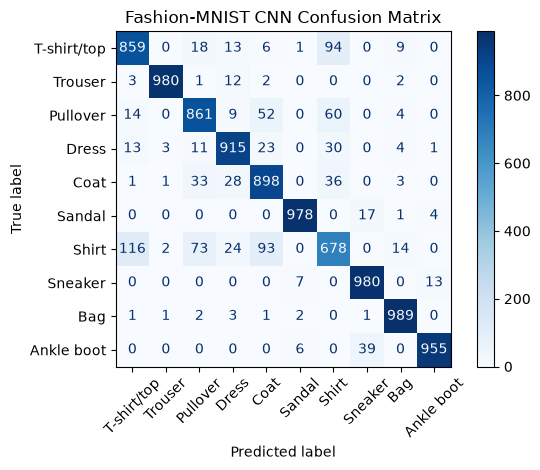

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Generate predictions
y_pred_prob = model.predict(x_test)
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print("CLASSIFICATION REPORT")
print("=" * 65)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Fashion-MNIST CNN Confusion Matrix")
plt.tight_layout()
plt.show()

Total Incorrect Predictions: 907
Total Test Images: 10000


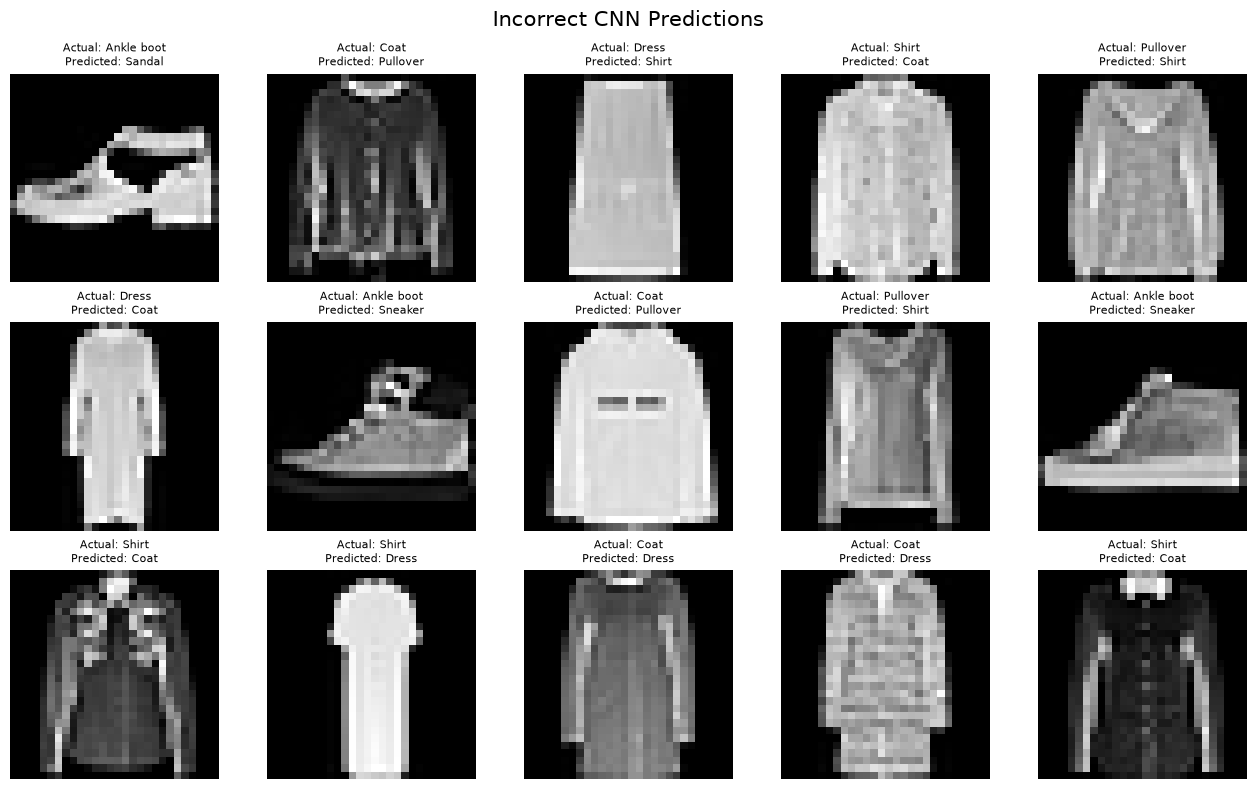

In [13]:
# Find incorrectly classified images
incorrect_indices = np.where(y_pred != y_test)[0]

print("Total Incorrect Predictions:", len(incorrect_indices))
print("Total Test Images:", len(y_test))

# Display the first 15 incorrect predictions
plt.figure(figsize=(13, 8))

for i, idx in enumerate(incorrect_indices[:15]):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_test[idx].squeeze(), cmap="gray")

    actual = class_names[y_test[idx]]
    predicted = class_names[y_pred[idx]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=8
    )

    plt.axis("off")

plt.suptitle("Incorrect CNN Predictions", fontsize=15)
plt.tight_layout()
plt.show()

In [14]:
import os

# Save the trained CNN model
model.save("Fashion_MNIST_CNN.keras")

print("Model saved successfully!")

# Verify the saved model
file_path = "Fashion_MNIST_CNN.keras"

if os.path.exists(file_path):
    print("File exists:", True)
    print("File size:", round(os.path.getsize(file_path) / (1024 * 1024), 2), "MB")
else:
    print("Model file not found!")

Model saved successfully!
File exists: True
File size: 2.61 MB


In [15]:
# Load the saved CNN model
loaded_model = keras.models.load_model("Fashion_MNIST_CNN.keras")

print("Saved model loaded successfully!")

# Evaluate the loaded model
loaded_loss, loaded_accuracy = loaded_model.evaluate(
    x_test, y_test, verbose=1
)

print("\nLoaded Model Test Loss:", round(loaded_loss, 4))
print("Loaded Model Test Accuracy:", round(loaded_accuracy * 100, 2), "%")

# Compare with the original model
print("\nOriginal Model Accuracy:", round(test_accuracy * 100, 2), "%")
print("Loaded Model Accuracy:", round(loaded_accuracy * 100, 2), "%")

Saved model loaded successfully!
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9093 - loss: 0.2466

Loaded Model Test Loss: 0.2466
Loaded Model Test Accuracy: 90.93 %

Original Model Accuracy: 90.93 %
Loaded Model Accuracy: 90.93 %


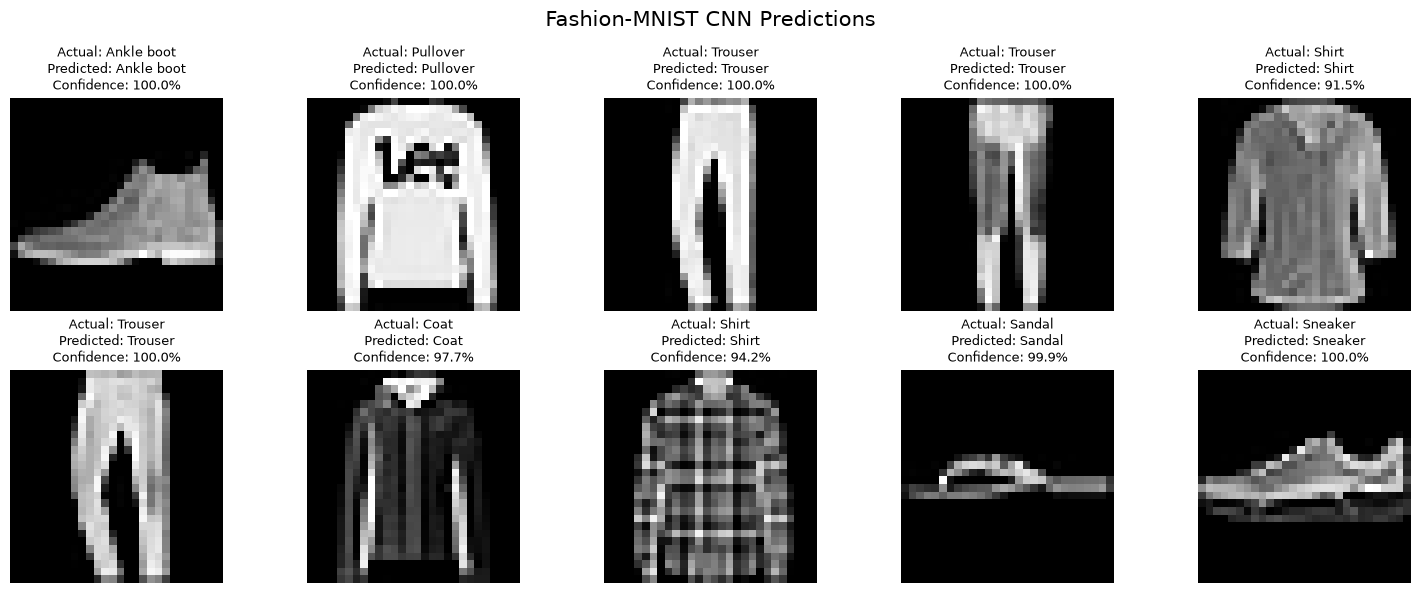

In [16]:
# Select 10 test images
sample_images = x_test[:10]
actual_labels = y_test[:10]

# Generate predictions using the saved model
predictions = loaded_model.predict(sample_images, verbose=0)

predicted_labels = np.argmax(predictions, axis=1)
confidence_scores = np.max(predictions, axis=1) * 100

# Display predictions
plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(sample_images[i].squeeze(), cmap="gray")

    actual = class_names[actual_labels[i]]
    predicted = class_names[predicted_labels[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}\nConfidence: {confidence_scores[i]:.1f}%",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("Fashion-MNIST CNN Predictions", fontsize=15)
plt.tight_layout()
plt.show()

CLASSIFICATION REPORT

              precision    recall  f1-score   support

 T-shirt/top     0.8530    0.8590    0.8560      1000
     Trouser     0.9929    0.9800    0.9864      1000
    Pullover     0.8619    0.8610    0.8614      1000
       Dress     0.9114    0.9150    0.9132      1000
        Coat     0.8353    0.8980    0.8655      1000
      Sandal     0.9839    0.9780    0.9809      1000
       Shirt     0.7550    0.6780    0.7144      1000
     Sneaker     0.9450    0.9800    0.9622      1000
         Bag     0.9639    0.9890    0.9763      1000
  Ankle boot     0.9815    0.9550    0.9681      1000

    accuracy                         0.9093     10000
   macro avg     0.9084    0.9093    0.9085     10000
weighted avg     0.9084    0.9093    0.9085     10000



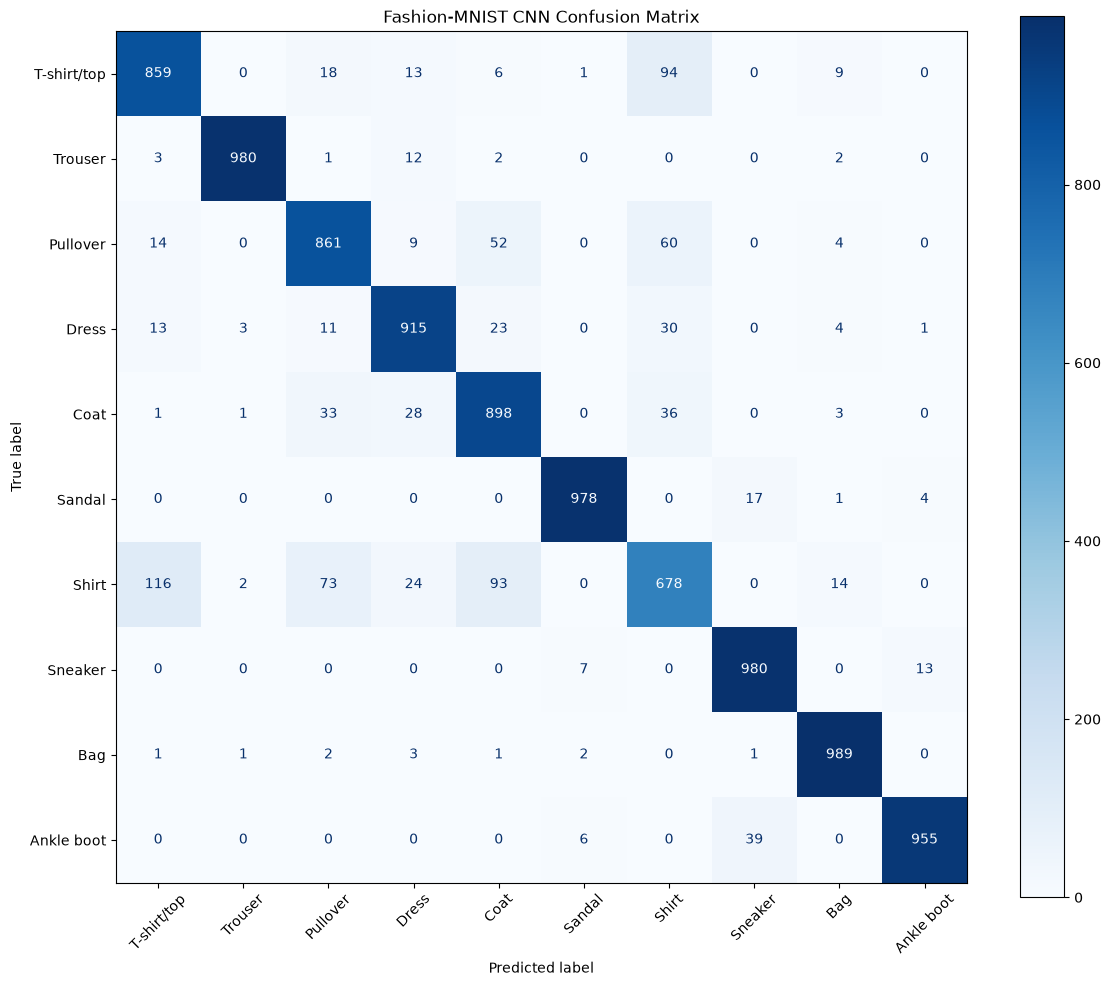

In [17]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Generate predictions for the complete test dataset
y_pred = np.argmax(loaded_model.predict(x_test, verbose=0), axis=1)

# Classification report
print("CLASSIFICATION REPORT\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(cmap="Blues", xticks_rotation=45, ax=ax, values_format="d")
plt.title("Fashion-MNIST CNN Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd
import numpy as np

class_correct = np.diag(cm)
class_total = np.sum(cm, axis=1)

class_accuracy = (class_correct / class_total) * 100

class_results = pd.DataFrame({
    "Fashion Category": class_names,
    "Correct Predictions": class_correct,
    "Total Images": class_total,
    "Accuracy (%)": np.round(class_accuracy, 2)
})

print(class_results.to_string(index=False))

print("\nOverall Correct Predictions:", np.sum(y_pred == y_test))
print("Overall Incorrect Predictions:", np.sum(y_pred != y_test))

Fashion Category  Correct Predictions  Total Images  Accuracy (%)
     T-shirt/top                  859          1000          85.9
         Trouser                  980          1000          98.0
        Pullover                  861          1000          86.1
           Dress                  915          1000          91.5
            Coat                  898          1000          89.8
          Sandal                  978          1000          97.8
           Shirt                  678          1000          67.8
         Sneaker                  980          1000          98.0
             Bag                  989          1000          98.9
      Ankle boot                  955          1000          95.5

Overall Correct Predictions: 9093
Overall Incorrect Predictions: 907


In [19]:
# Generate probabilities for all 10,000 test images
y_prob = loaded_model.predict(x_test, verbose=0)

y_pred = np.argmax(y_prob, axis=1)
confidence = np.max(y_prob, axis=1) * 100

# Create results table
prediction_results = pd.DataFrame({
    "Actual_Label": y_test,
    "Predicted_Label": y_pred,
    "Actual_Class": [class_names[i] for i in y_test],
    "Predicted_Class": [class_names[i] for i in y_pred],
    "Confidence_Percent": np.round(confidence, 2),
    "Correct_Prediction": y_test == y_pred
})

# Export CSV
prediction_results.to_csv("Fashion_MNIST_Prediction_Results.csv", index=False)

print("Prediction results exported successfully!")
print("Total records:", len(prediction_results))
print("Correct predictions:", prediction_results["Correct_Prediction"].sum())
print("Incorrect predictions:", (~prediction_results["Correct_Prediction"]).sum())
print("\nFirst 5 records:")
display(prediction_results.head())

Prediction results exported successfully!
Total records: 10000
Correct predictions: 9093
Incorrect predictions: 907

First 5 records:


,Actual_Label,Predicted_Label,Actual_Class,Predicted_Class,Confidence_Percent,Correct_Prediction
0,9,9,Ankle boot,Ankle boot,100.000000,True
1,2,2,Pullover,Pullover,100.000000,True
2,1,1,Trouser,Trouser,100.000000,True
3,1,1,Trouser,Trouser,100.000000,True
4,6,6,Shirt,Shirt,91.540001,True


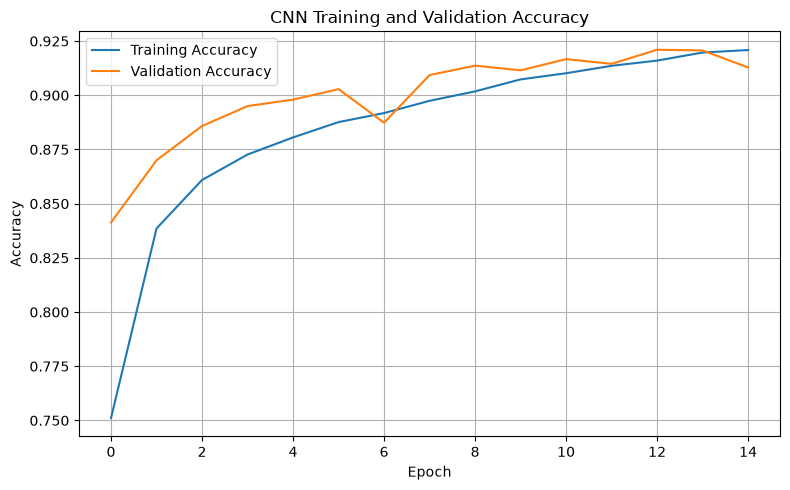

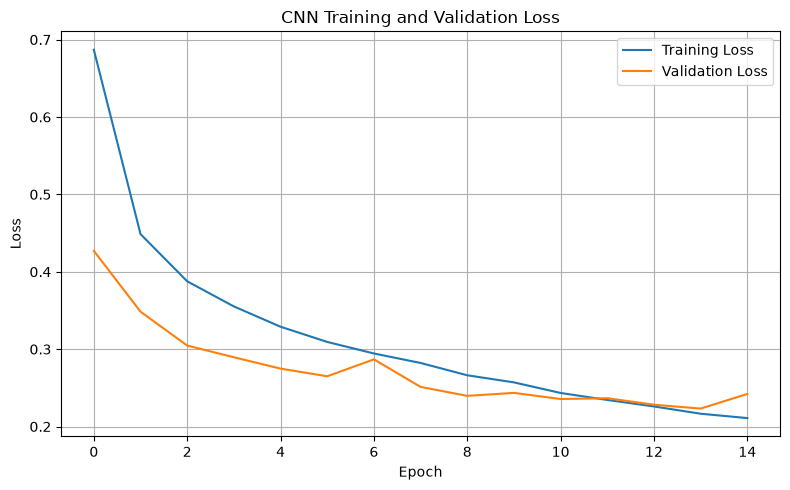

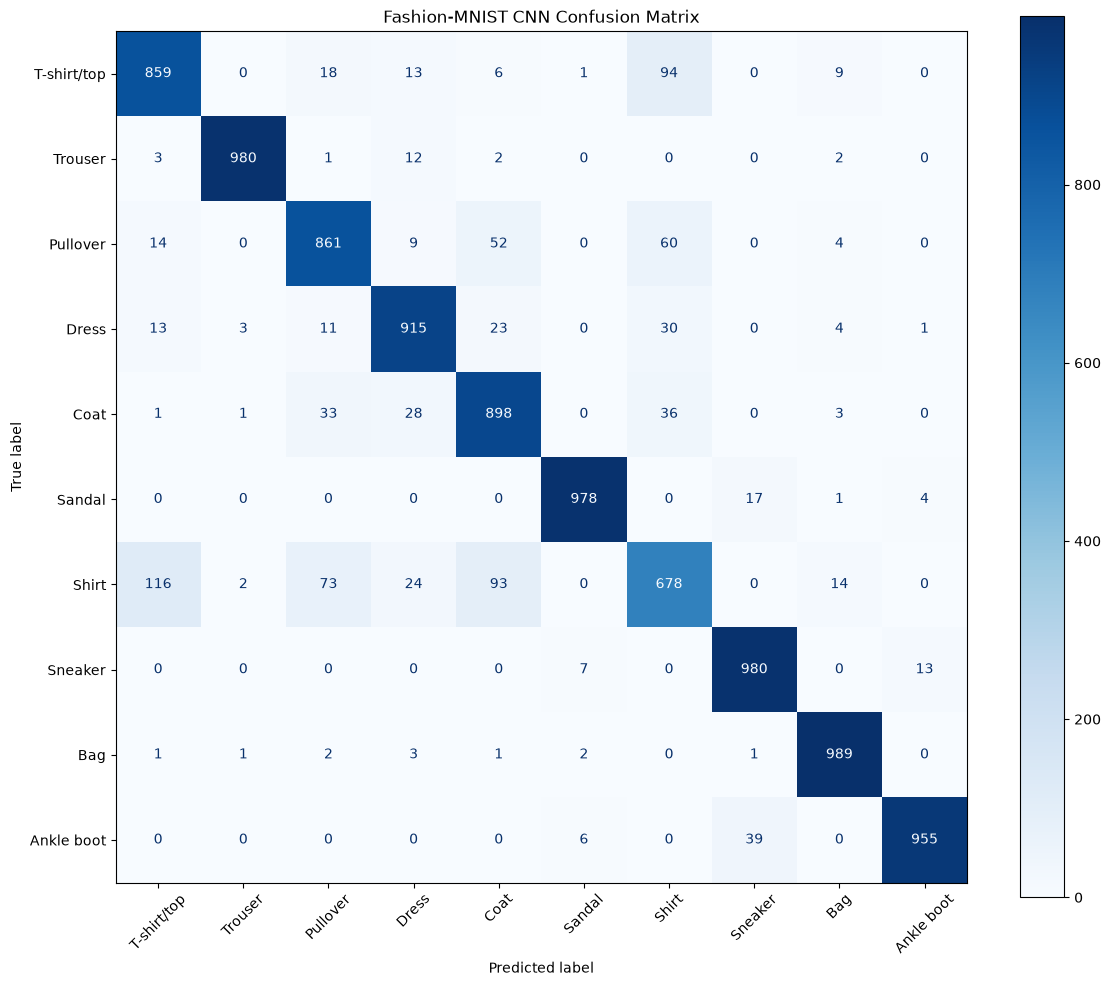


Graph file verification:
Training_Validation_Accuracy.png -> Saved
Training_Validation_Loss.png -> Saved
Confusion_Matrix.png -> Saved


In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import numpy as np

# 1. Save training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("Training_Validation_Accuracy.png", dpi=300)
plt.show()

# 2. Save training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("Training_Validation_Loss.png", dpi=300)
plt.show()

# 3. Save confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", xticks_rotation=45, ax=ax, values_format="d")
plt.title("Fashion-MNIST CNN Confusion Matrix")
plt.tight_layout()
plt.savefig("Confusion_Matrix.png", dpi=300)
plt.show()

# 4. Verify saved graph files
import os

graph_files = [
    "Training_Validation_Accuracy.png",
    "Training_Validation_Loss.png",
    "Confusion_Matrix.png"
]

print("\nGraph file verification:")
for file in graph_files:
    print(file, "->", "Saved" if os.path.exists(file) else "Not Found")